**baseline modelling**
- relevant dataset only
- one hot encoding categorical features
- sample balancing ???
- logistic regression
- random forest

In [1]:
from helper_functions.data_processing import get_cleaned_data
from helper_functions.model_building import *
data, numerical_cols, categorical_cols = get_cleaned_data()

Missing values before imputation: 30

Filled out missing values.

Missing values after imputation: 0

In [21]:
preprocessor = get_preprocessor(data, numerical_cols, categorical_cols)
X_train, X_test, y_train, y_test = get_train_test_data(data)

Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64


## Class Balancing

### With PCA decomposition

Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64
Evaluating: None (Class Weight Only)
Evaluating: SMOTE
Evaluating: Borderline-SMOTE
Evaluating: ADASYN
Evaluating: SMOTEENN
Evaluating: SMOTETomek


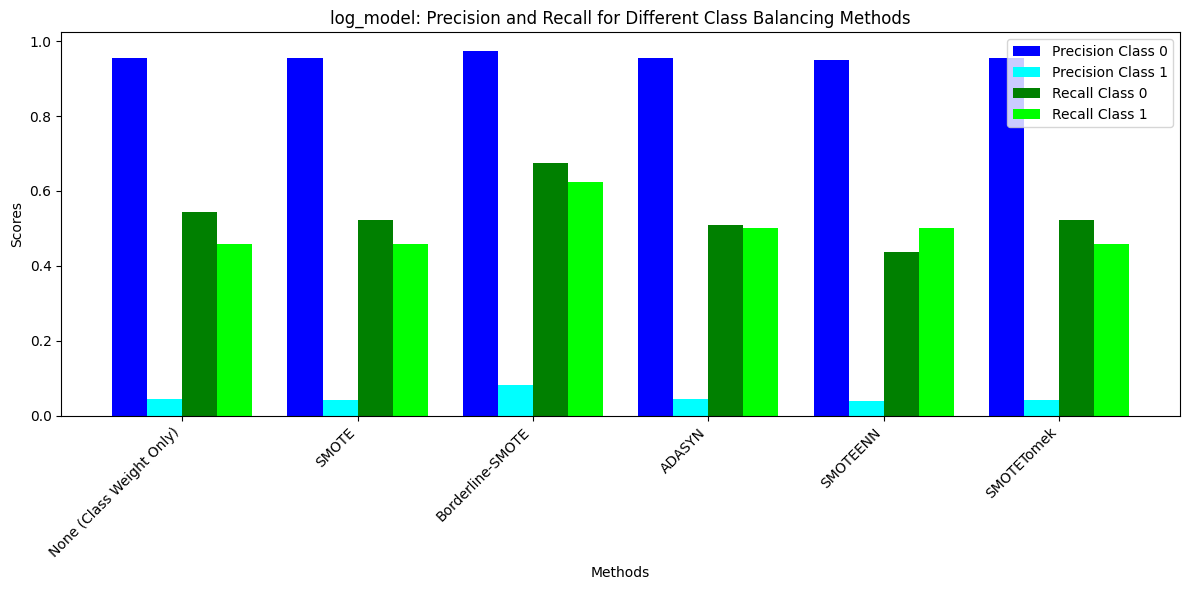

In [22]:
from sklearn.linear_model import LogisticRegression
results_log = evaluate_methods(
    data, 
    preprocessor,
    PCA(n_components=n_components), 
    LogisticRegression(class_weight='balanced', random_state=42),
    "log_model")

Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64
Evaluating: None (Class Weight Only)
Evaluating: SMOTE
Evaluating: Borderline-SMOTE
Evaluating: ADASYN
Evaluating: SMOTEENN
Evaluating: SMOTETomek


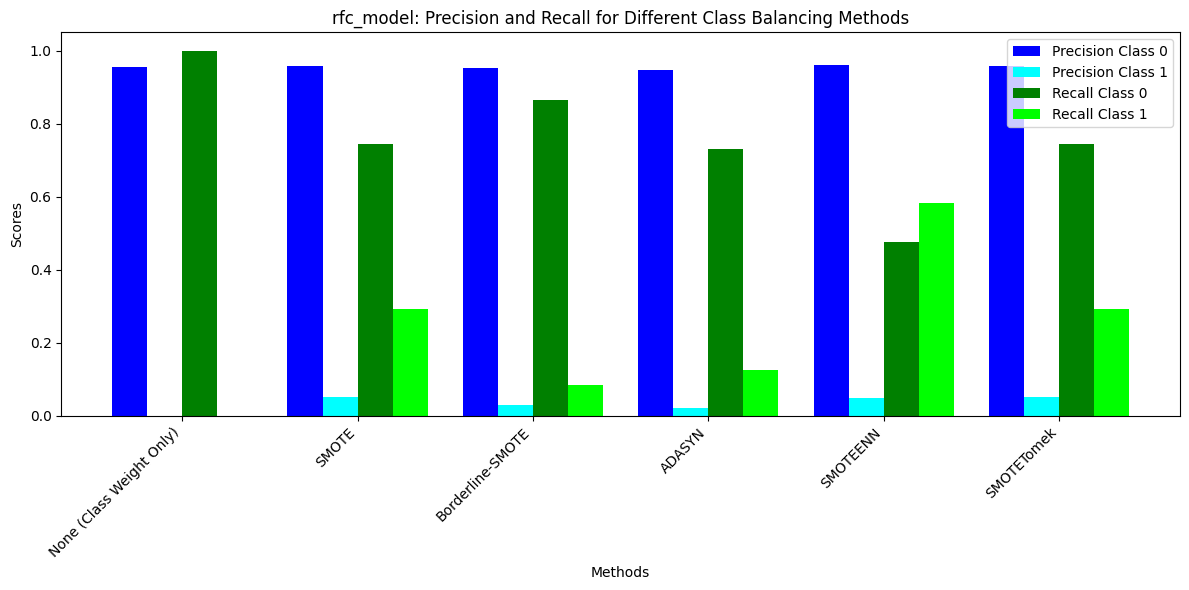

In [23]:
results_rfc = evaluate_methods(
    data, 
    preprocessor, 
    PCA(n_components=n_components), 
    RandomForestClassifier(class_weight='balanced', random_state=42),
    "rfc_model")

Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64
Evaluating: None (Class Weight Only)
Evaluating: SMOTE
Evaluating: Borderline-SMOTE
Evaluating: ADASYN
Evaluating: SMOTEENN
Evaluating: SMOTETomek


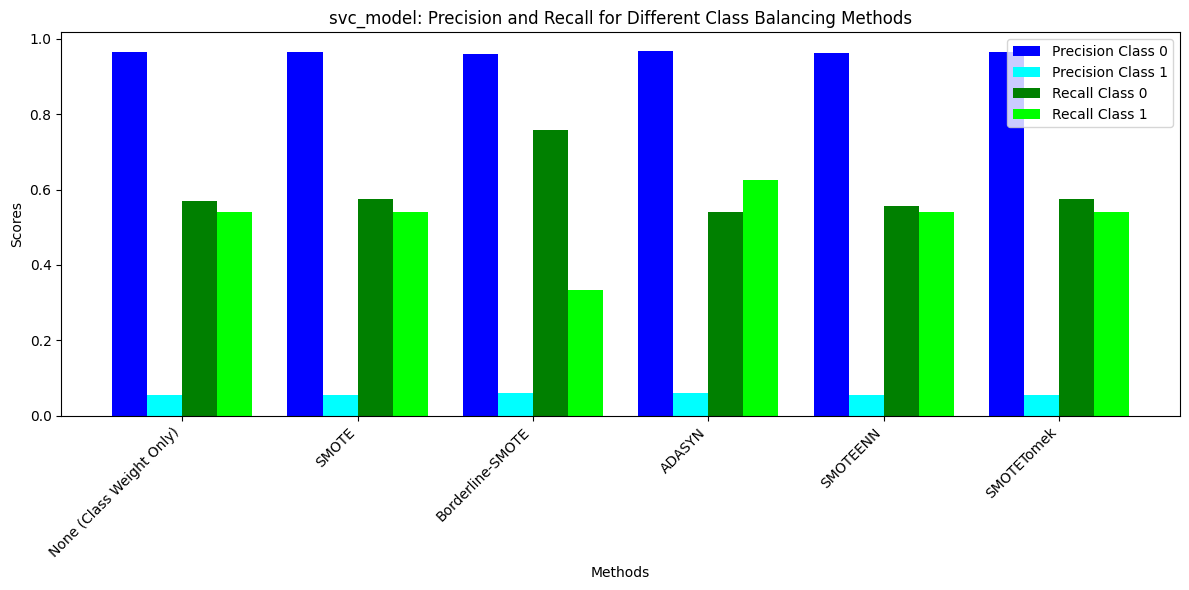

In [24]:
results_svc = evaluate_methods(
    data, 
    preprocessor, 
    PCA(n_components=n_components), 
    SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=42),
    "svc_model")

Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64
Evaluating: None (Class Weight Only)
Evaluating: SMOTE
Evaluating: Borderline-SMOTE
Evaluating: ADASYN
Evaluating: SMOTEENN
Evaluating: SMOTETomek


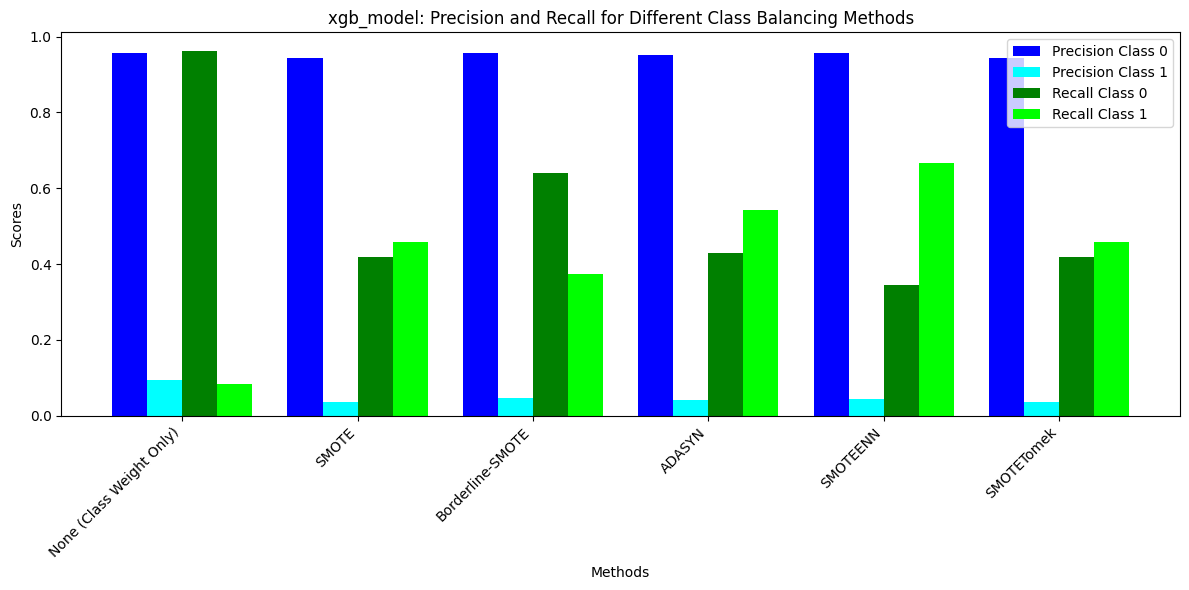

In [25]:
from xgboost import XGBClassifier
# Calculate scale_pos_weight
pos_weight = len(y_train[y_train == 0]) / len(y_train[y_train == 1])
results_xgb = evaluate_methods(
    data,
    preprocessor, 
    PCA(n_components=n_components), 
    XGBClassifier(scale_pos_weight=pos_weight, eval_metric='logloss', random_state=42),
    "xgb_model")

Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64
Evaluating: None (Class Weight Only)
Evaluating: SMOTE
Evaluating: Borderline-SMOTE
Evaluating: ADASYN
Evaluating: SMOTEENN
Evaluating: SMOTETomek


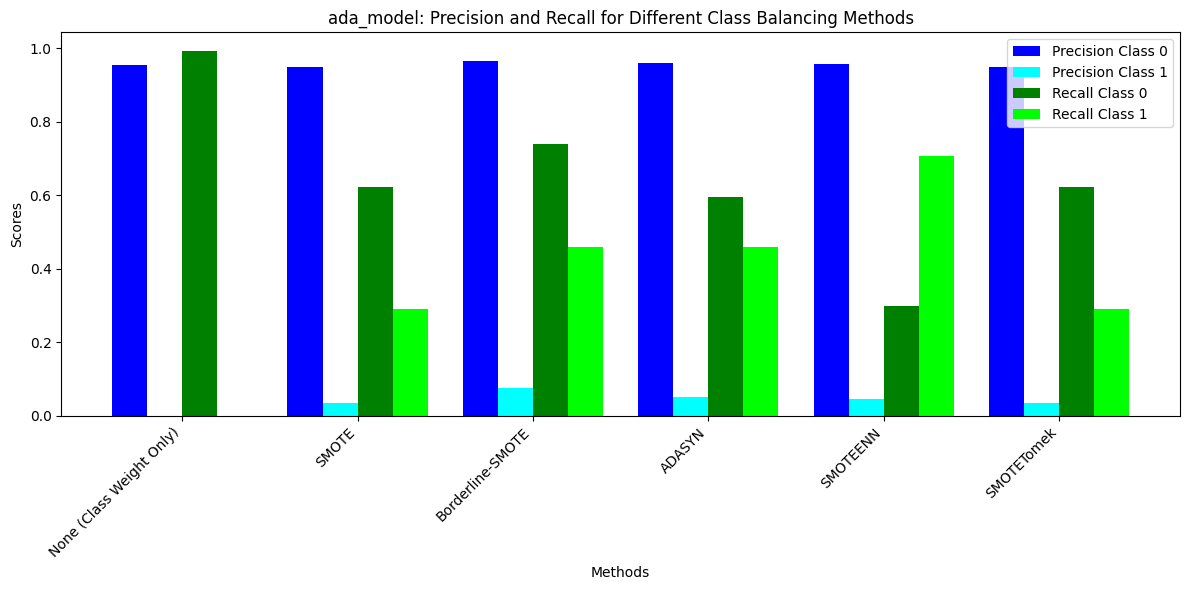

Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64
Evaluating: None (Class Weight Only)
Evaluating: SMOTE
Evaluating: Borderline-SMOTE
Evaluating: ADASYN
Evaluating: SMOTEENN
Evaluating: SMOTETomek


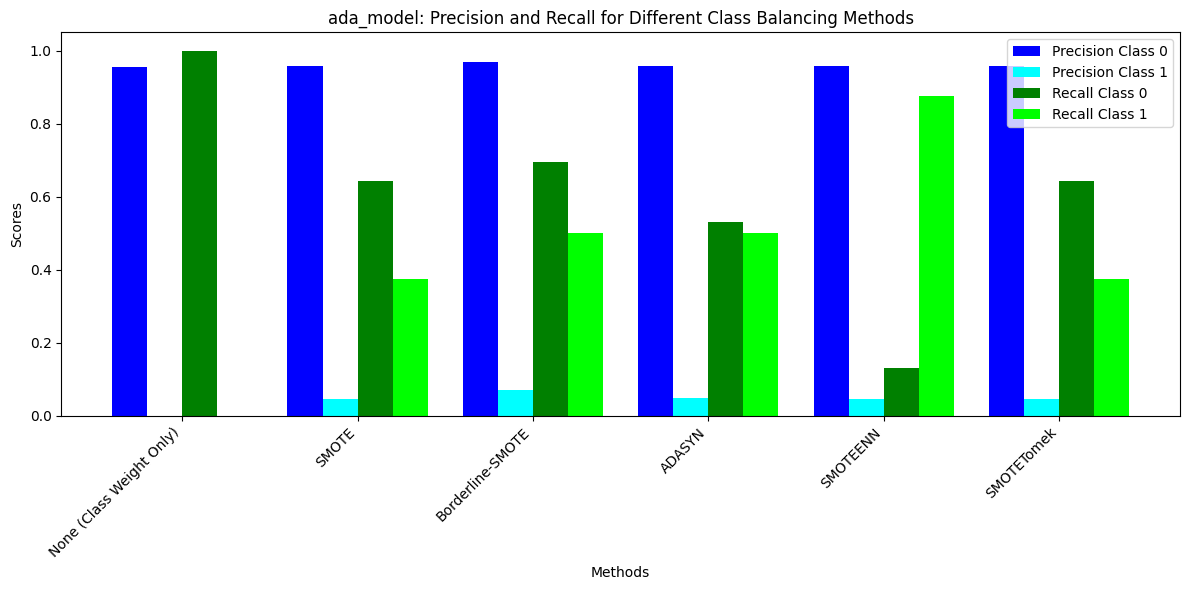

In [26]:
from sklearn.ensemble import AdaBoostClassifier

results_ada = evaluate_methods(
    data,
    preprocessor, 
    PCA(n_components=n_components), 
    AdaBoostClassifier(n_estimators=100, random_state=42),
    "ada_model")


results_ada2 = evaluate_methods(
    data,
    preprocessor, 
    PCA(n_components=n_components), 
    AdaBoostClassifier(n_estimators=100, random_state=42, algorithm='SAMME'),
    "ada_model")


In [27]:
results =     [('Logistic Regression', results_log),
              ('Random Forest', results_rfc),
              ('SVC', results_svc),
              ('XGBoost', results_xgb),
              ('ADA', results_ada),
              ('ADA2', results_ada2)]
plot_comparison_results(results)

### With PCA decomposition BEFORE SMOTE

In [9]:
results =     [('Logistic Regression', results_log),
              ('Random Forest', results_rfc),
              ('SVC', results_svc),
              ('XGBoost', results_xgb),
              ('ADA', results_ada)]
plot_comparison_results(results)

### Without PCA decomposition

Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64
Evaluating: None (Class Weight Only)


/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.



Evaluating: SMOTE
Evaluating: Borderline-SMOTE
Evaluating: ADASYN
Evaluating: SMOTEENN
Evaluating: SMOTETomek


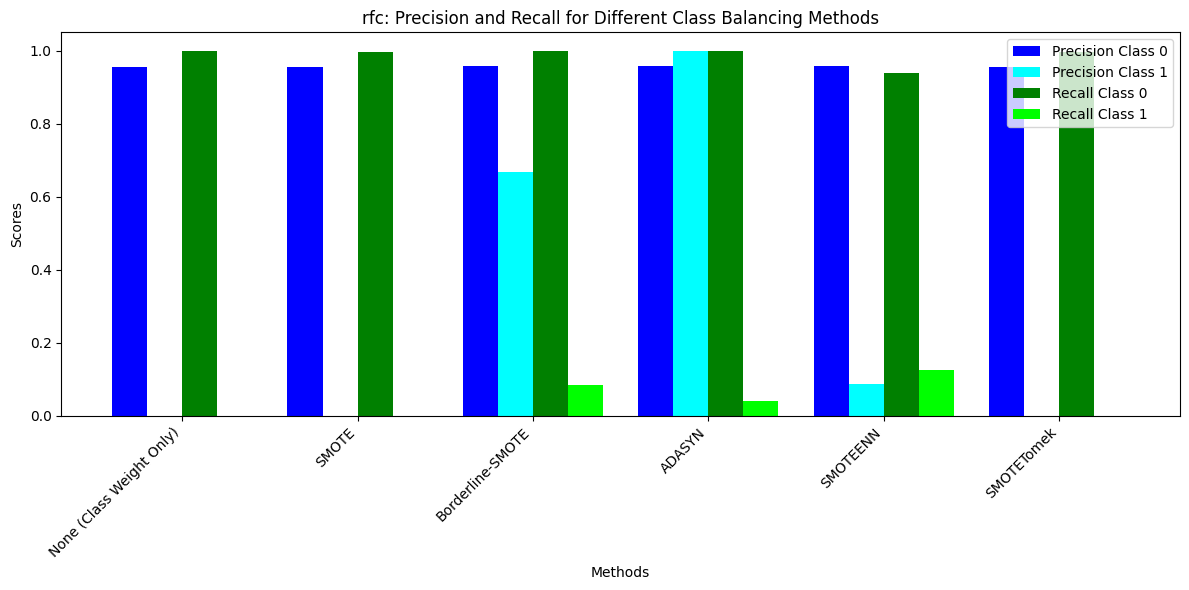

Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64
Evaluating: None (Class Weight Only)
Evaluating: SMOTE
Evaluating: Borderline-SMOTE
Evaluating: ADASYN
Evaluating: SMOTEENN
Evaluating: SMOTETomek


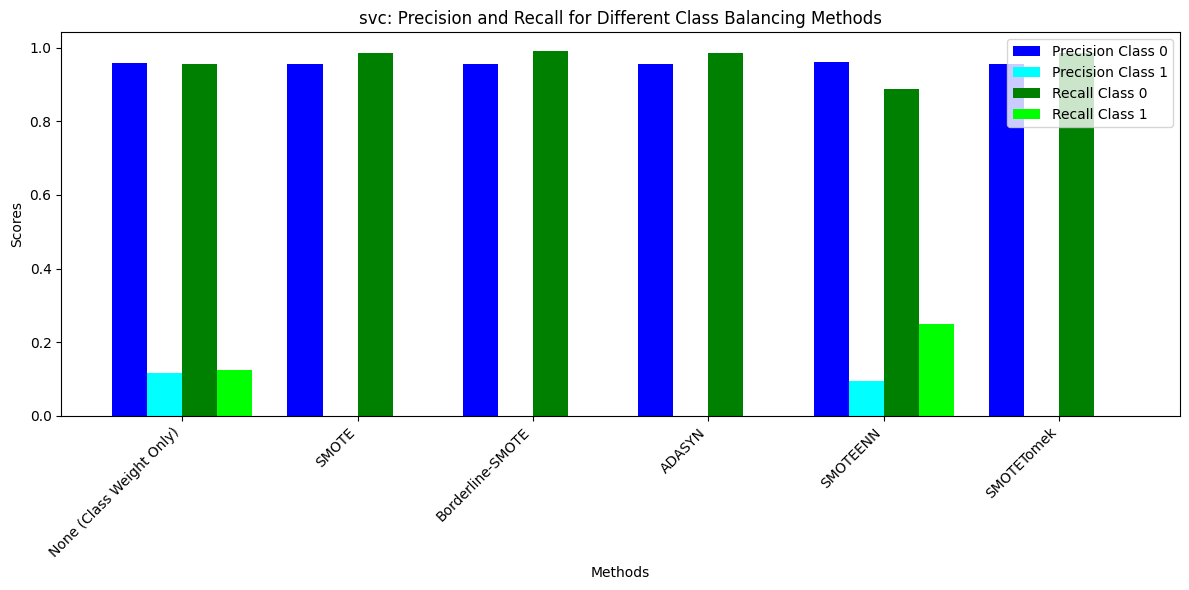

Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64
Evaluating: None (Class Weight Only)
Evaluating: SMOTE
Evaluating: Borderline-SMOTE
Evaluating: ADASYN
Evaluating: SMOTEENN
Evaluating: SMOTETomek


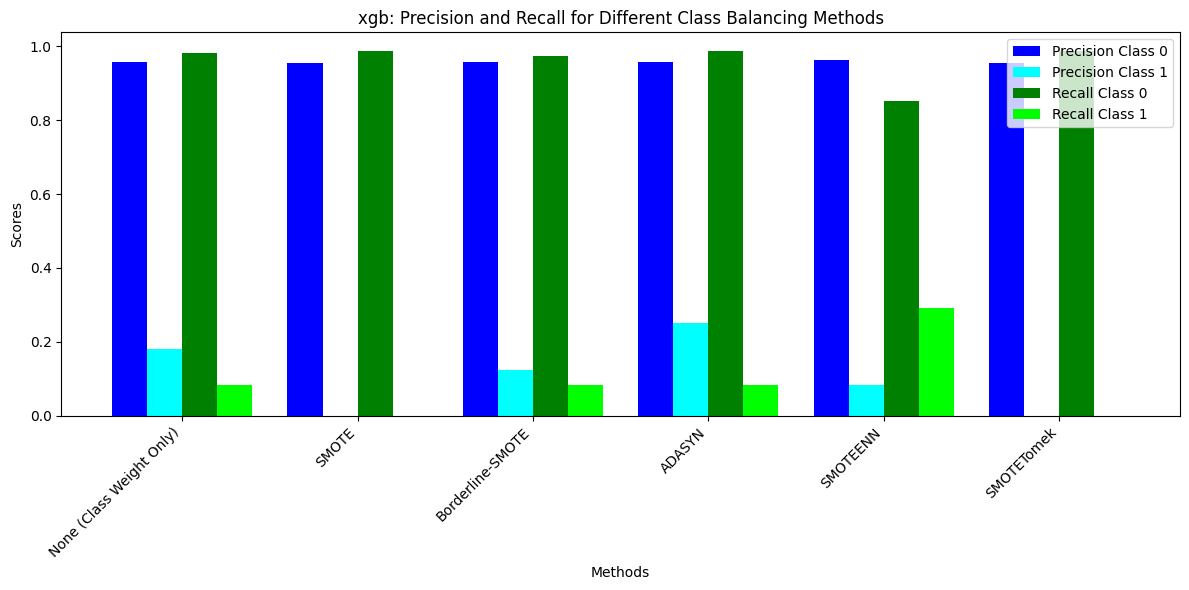

Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64
Evaluating: None (Class Weight Only)


/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning:

The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.



Evaluating: SMOTE


/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning:

The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.



Evaluating: Borderline-SMOTE


/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning:

The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.



... (2 outputs left out)

Evaluating: SMOTEENN


/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning:

The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.



Evaluating: SMOTETomek


/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning:

The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.



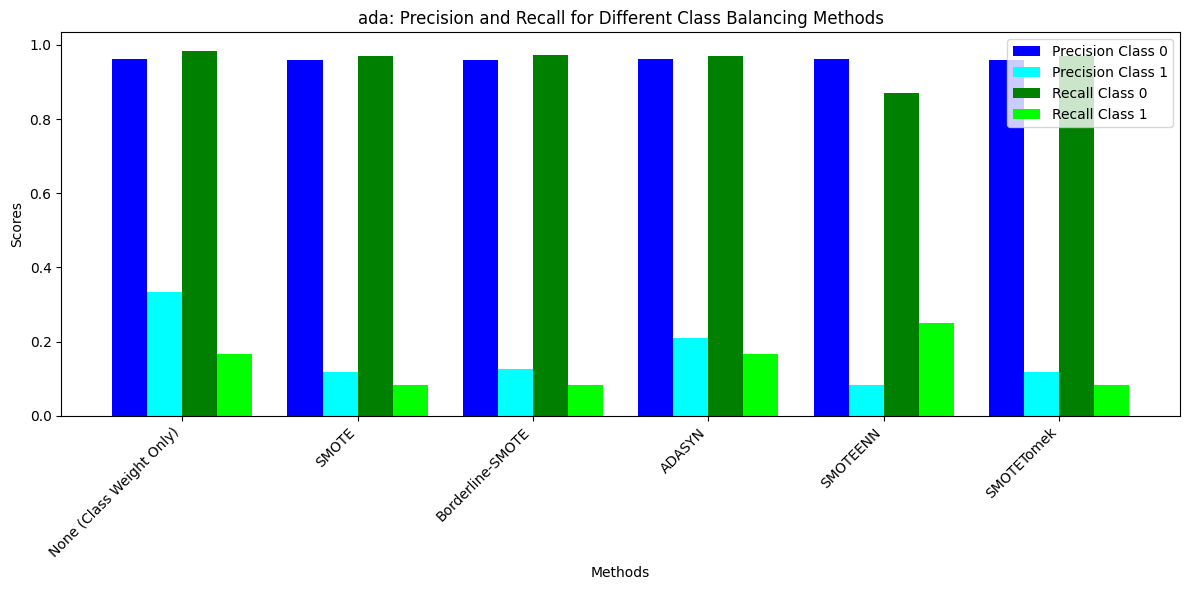

In [10]:
results_rfc_sans_pca = evaluate_methods(data, preprocessor, None, RandomForestClassifier(class_weight='balanced', random_state=42), "rfc")
results_svc_sans_pca = evaluate_methods(data, preprocessor, None, SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=42), "svc")
results_xgb_sans_pca = evaluate_methods(data, preprocessor,  None, XGBClassifier(scale_pos_weight=pos_weight, eval_metric='logloss', random_state=42), "xgb" )
results_ada_sans_pca = evaluate_methods(data, preprocessor,  None, AdaBoostClassifier(n_estimators=100, random_state=42), "ada" )
results =     [
            #   ('Logistic Regression', results_log),
              ('Random Forest', results_rfc_sans_pca),
              ('SVC', results_svc_sans_pca),
              ('XGBoost', results_xgb_sans_pca),
              ('ADA', results_ada)]
plot_comparison_results(results)

Feature analysis (and engineering??):

* getting the dominant features from the no-PCA model runs
* getting the PCA most significant components from the PCA model runs.
* pipeline -> PCA

--- finding out about the feature extraction N_features??? in the pipeline??? > lighthouse lab notes

Other models to try:
* logistic regression
* ADABoost 
* Gradient Booster

Metrics:
* add f1 score to the visuals, etc . for model-tuning? f2 score???

## Hypertuning ADABoost

In [28]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, fbeta_score
from tqdm.notebook import tqdm
import time
import warnings



smoteenn = SMOTEENN(random_state=42)


# Replace XGBClassifier with AdaBoostClassifier
ada_for_hyptertuning = AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=42), random_state=42, algorithm='SAMME')

# Define the pipeline
pipeline = ImbPipeline([
    ('preprocessor', preprocessor),
    ('oversample', smoteenn),
    ('classifier', ada_for_hyptertuning)
])

# Define the parameter grid for AdaBoost
param_grid = {
    'classifier__n_estimators': [50, 100, 150],  # Number of weak learners
    'classifier__learning_rate': [0.01, 0.1, 0.2, 1.0],  # Learning rate
    'classifier__estimator__max_depth': [1, 3, 5],  # Depth of the weak learner (DecisionTreeClassifier)
    'classifier__estimator__min_samples_split': [2, 5, 10],  # Min samples for a split
    'classifier__estimator__min_samples_leaf': [1, 2, 4]  # Min samples per leaf
}


# Fit pipeline
try:
    pipeline.fit(X_train, y_train)
except Exception as e:
    print(e)
    raise



# Define the scorer
f2_scorer = make_scorer(fbeta_score, beta=2, average='binary', pos_label=1)

# Perform grid search
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring=f2_scorer,
    cv=5,  # 5-fold cross-validation
    verbose=2,
    n_jobs=-1
)
warnings.filterwarnings("ignore")
grid_search.fit(X_train, y_train)
# Output the best parameters and the corresponding score
print("Best Parameters:", grid_search.best_params_)
print("Best F1-Score:", grid_search.best_score_)

Fitting 5 folds for each of 324 candidates, totalling 1620 fits
[CV] END classifier__estimator__max_depth=1, classifier__estimator__min_samples_leaf=1, classifier__estimator__min_samples_split=2, classifier__learning_rate=0.01, classifier__n_estimators=50; total time=   2.8s
[CV] END classifier__estimator__max_depth=1, classifier__estimator__min_samples_leaf=1, classifier__estimator__min_samples_split=2, classifier__learning_rate=0.01, classifier__n_estimators=50; total time=   2.9s
[CV] END classifier__estimator__max_depth=1, classifier__estimator__min_samples_leaf=1, classifier__estimator__min_samples_split=2, classifier__learning_rate=0.01, classifier__n_estimators=50; total time=   2.9s
[CV] END classifier__estimator__max_depth=1, classifier__estimator__min_samples_leaf=1, classifier__estimator__min_samples_split=2, classifier__learning_rate=0.01, classifier__n_estimators=50; total time=   2.9s
[CV] END classifier__estimator__max_depth=1, classifier__estimator__min_samples_leaf=1, 

Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64
Evaluating: None (Class Weight Only)
Evaluating: SMOTE
Evaluating: Borderline-SMOTE
Evaluating: ADASYN
Evaluating: SMOTEENN
Evaluating: SMOTETomek


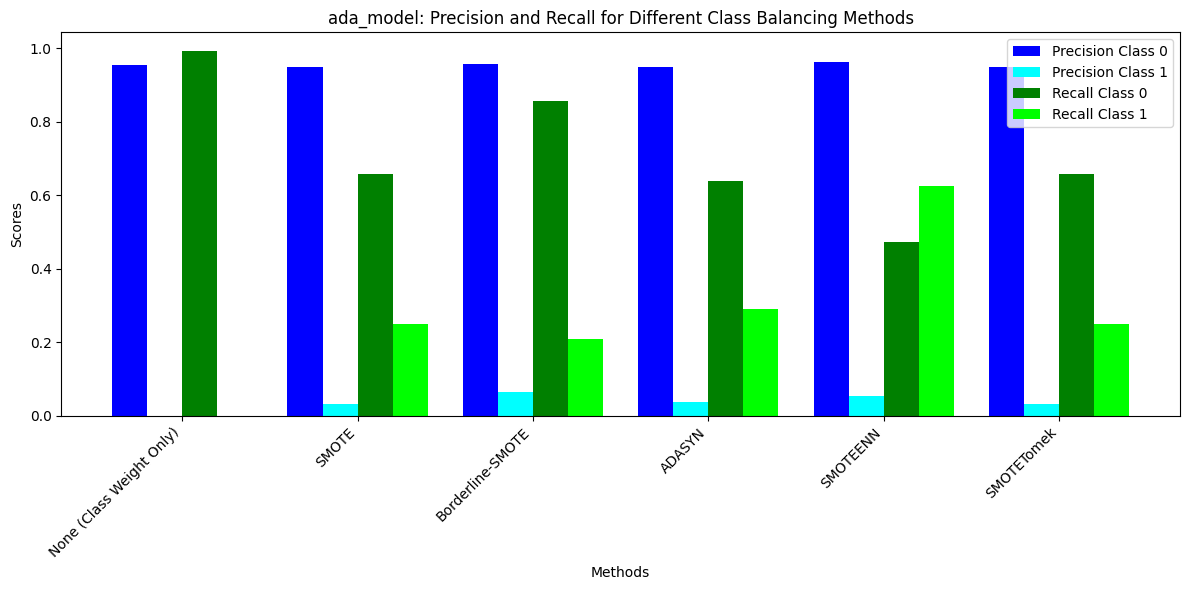

In [31]:
best_ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=2,
        min_samples_split=2,
        random_state=42), 
    learning_rate=1.0,
    random_state=42, 
    algorithm='SAMME')

# Define the pipeline
results_best_ada = evaluate_methods(
    data,
    preprocessor, 
    PCA(n_components=n_components), 
    best_ada,
    "ada_model")

* Using a custom metric. Which ended up being a dead-end but it was worthwhile to explore this for a while.

In [32]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, recall_score
from tqdm.notebook import tqdm
import time
import warnings



smoteenn = SMOTEENN(random_state=42)


# Replace XGBClassifier with AdaBoostClassifier
ada_for_hyptertuning = AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=42), random_state=42, algorithm='SAMME')

# Define the pipeline
pipeline = ImbPipeline([
    ('preprocessor', preprocessor),
    ('oversample', smoteenn),
    ('classifier', ada_for_hyptertuning)
])

# Define the parameter grid for AdaBoost
param_grid = {
    'classifier__n_estimators': [50, 100, 150],  # Number of weak learners
    'classifier__learning_rate': [0.01, 0.1, 0.2, 1.0],  # Learning rate
    'classifier__estimator__max_depth': [1, 3, 5],  # Depth of the weak learner (DecisionTreeClassifier)
    'classifier__estimator__min_samples_split': [2, 5, 10],  # Min samples for a split
    'classifier__estimator__min_samples_leaf': [1, 2, 4]  # Min samples per leaf
}


# Fit pipeline
try:
    pipeline.fit(X_train, y_train)
except Exception as e:
    print(e)
    raise



# Define the scorer
f2_scorer = make_scorer(recall_score, average='binary', pos_label=1)

# Perform grid search
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring=f2_scorer,
    cv=5,  # 5-fold cross-validation
    verbose=2,
    n_jobs=-1
)
warnings.filterwarnings("ignore")
grid_search.fit(X_train, y_train)
# Output the best parameters and the corresponding score
print("Best Parameters:", grid_search.best_params_)
print("Best F1-Score:", grid_search.best_score_)

Fitting 5 folds for each of 324 candidates, totalling 1620 fits
[CV] END classifier__estimator__max_depth=1, classifier__estimator__min_samples_leaf=1, classifier__estimator__min_samples_split=2, classifier__learning_rate=0.01, classifier__n_estimators=50; total time=   3.8s
[CV] END classifier__estimator__max_depth=1, classifier__estimator__min_samples_leaf=1, classifier__estimator__min_samples_split=2, classifier__learning_rate=0.01, classifier__n_estimators=50; total time=   3.8s
[CV] END classifier__estimator__max_depth=1, classifier__estimator__min_samples_leaf=1, classifier__estimator__min_samples_split=2, classifier__learning_rate=0.01, classifier__n_estimators=50; total time=   3.8s
[CV] END classifier__estimator__max_depth=1, classifier__estimator__min_samples_leaf=1, classifier__estimator__min_samples_split=2, classifier__learning_rate=0.01, classifier__n_estimators=50; total time=   3.8s
[CV] END classifier__estimator__max_depth=1, classifier__estimator__min_samples_leaf=1, 

Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64
Evaluating: None (Class Weight Only)
Evaluating: SMOTE
Evaluating: Borderline-SMOTE
Evaluating: ADASYN
Evaluating: SMOTEENN
Evaluating: SMOTETomek


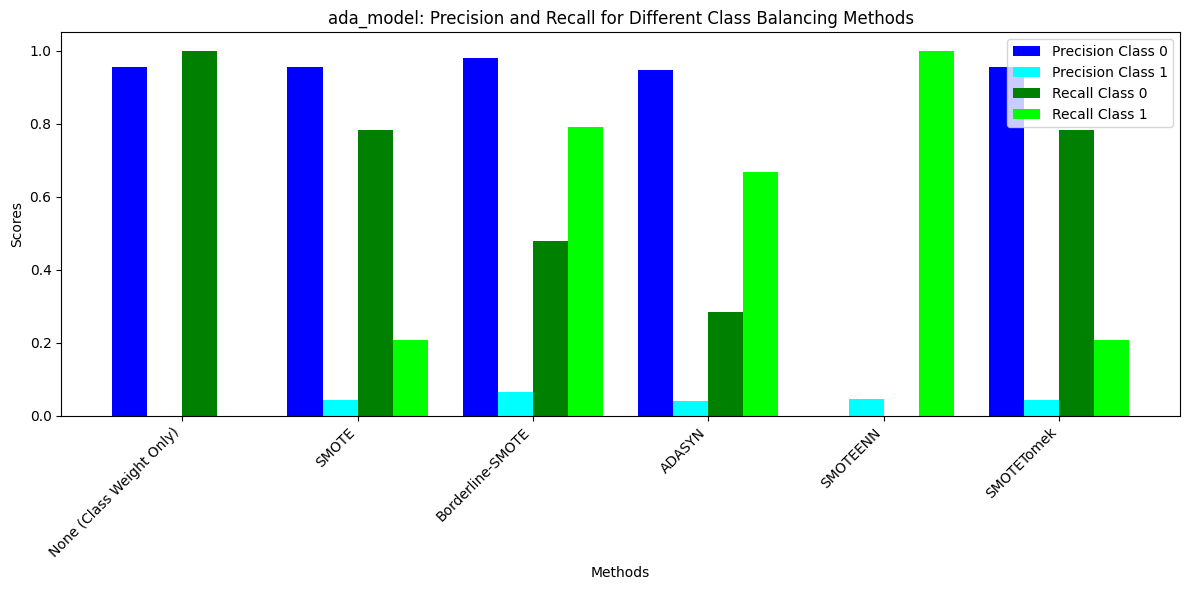

In [33]:
#best model
best_ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        min_samples_leaf=1,
        min_samples_split=2,
        random_state=42), 
    learning_rate=0.01,
    n_estimators=100,
    random_state=42, 
    algorithm='SAMME')

# Define the pipeline
results_best_ada = evaluate_methods(
    data,
    preprocessor, 
    PCA(n_components=n_components), 
    best_ada,
    "ada_model")

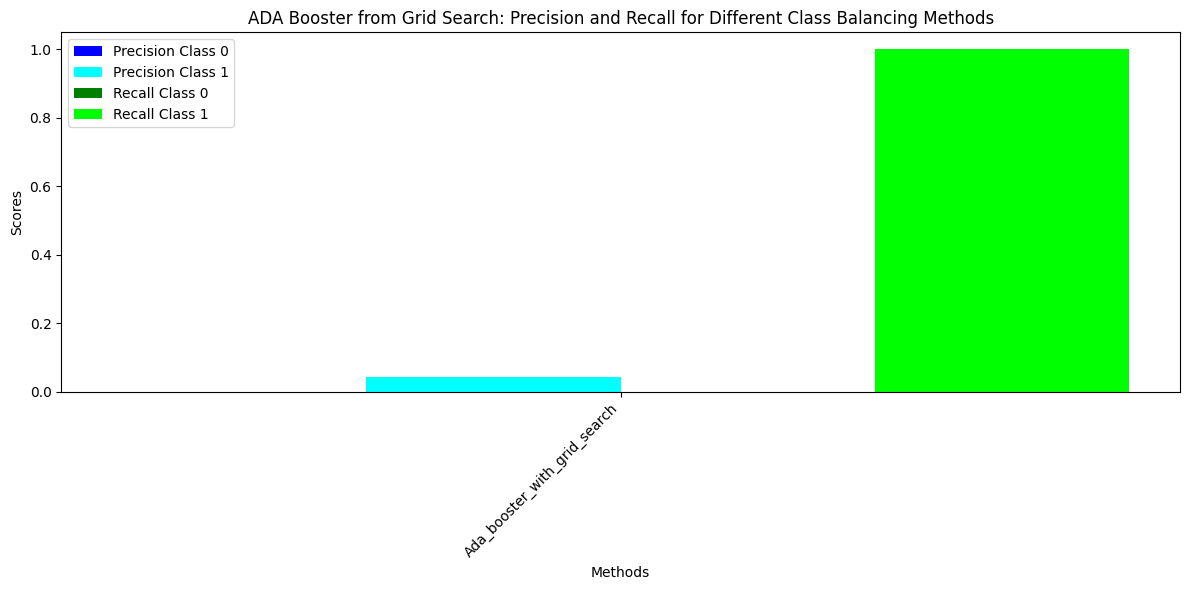

In [40]:
pipeline = grid_search

y_pred = pipeline.predict(X_test)

# Calculate precision and recall for both classes
precision_class_0 = precision_score(y_test, y_pred, pos_label=0)
precision_class_1 = precision_score(y_test, y_pred, pos_label=1)
recall_class_0 = recall_score(y_test, y_pred, pos_label=0)
recall_class_1 = recall_score(y_test, y_pred, pos_label=1)

# Store results
results = {}
results["Ada_booster_with_grid_search"] = {
    "precision_0": precision_class_0,
    "precision_1": precision_class_1,
    "recall_0": recall_class_0,
    "recall_1": recall_class_1
}

# Plot results
plot_results(results, "ADA Booster from Grid Search")

### Custom Metric based on the project specifications

In [42]:
from sklearn.metrics import roc_curve
from sklearn.metrics import make_scorer
def tpr_at_fpr_threshold(y_true, y_pred_proba, fpr_threshold=0.20):
    # Ensure y_pred_proba is a 1D array for probabilities of class 1
    if y_pred_proba.ndim > 1:
        y_pred_proba = y_pred_proba[:, 1]  # Extract probabilities for class 1
    
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_proba)
    # Find the maximum TPR where FPR <= fpr_threshold
    tpr_at_fpr = max((tpr[idx] for idx, fp_rate in enumerate(fpr) if fp_rate <= fpr_threshold), default=0)
    return tpr_at_fpr

custom_scorer = make_scorer(
    lambda y_true, y_pred: tpr_at_fpr_threshold(y_true, y_pred[:, 1]), 
    needs_proba=True)

# Replace XGBClassifier with AdaBoostClassifier
ada_for_hyptertuning = AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=42), random_state=42, algorithm='SAMME')

# Define the pipeline
pipeline = ImbPipeline([
    ('preprocessor', preprocessor),
    ('oversample', smoteenn),
    ('classifier', ada_for_hyptertuning)
])

# Define the parameter grid for AdaBoost
param_grid = {
    'classifier__n_estimators': [50, 100, 150],  # Number of weak learners
    'classifier__learning_rate': [0.01, 0.1, 0.2, 1.0],  # Learning rate
    'classifier__estimator__max_depth': [1, 3, 5],  # Depth of the weak learner (DecisionTreeClassifier)
    'classifier__estimator__min_samples_split': [2, 5, 10],  # Min samples for a split
    'classifier__estimator__min_samples_leaf': [1, 2, 4]  # Min samples per leaf
}


# Fit pipeline
try:
    pipeline.fit(X_train, y_train)
except Exception as e:
    print(e)
    raise


# Perform grid search
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring=custom_scorer,
    cv=5,  # 5-fold cross-validation
    verbose=2,
    n_jobs=-1
)
warnings.filterwarnings("ignore")
grid_search.fit(X_train, y_train)
# Output the best parameters and the corresponding score
print("Best Parameters:", grid_search.best_params_)
print("Best Custom Score:", grid_search.best_score_)

Fitting 5 folds for each of 324 candidates, totalling 1620 fits


/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/model_selection/_validation.py:982: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 971, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 279, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 376, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kw

[CV] END classifier__estimator__max_depth=1, classifier__estimator__min_samples_leaf=1, classifier__estimator__min_samples_split=2, classifier__learning_rate=0.01, classifier__n_estimators=50; total time=   2.7s
[CV] END classifier__estimator__max_depth=1, classifier__estimator__min_samples_leaf=1, classifier__estimator__min_samples_split=2, classifier__learning_rate=0.01, classifier__n_estimators=50; total time=   2.7s
[CV] END classifier__estimator__max_depth=1, classifier__estimator__min_samples_leaf=1, classifier__estimator__min_samples_split=2, classifier__learning_rate=0.01, classifier__n_estimators=50; total time=   2.7s
[CV] END classifier__estimator__max_depth=1, classifier__estimator__min_samples_leaf=1, classifier__estimator__min_samples_split=2, classifier__learning_rate=0.01, classifier__n_estimators=50; total time=   2.7s
[CV] END classifier__estimator__max_depth=1, classifier__estimator__min_samples_leaf=1, classifier__estimator__min_samples_split=2, classifier__learning

/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/model_selection/_validation.py:982: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 971, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 279, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 376, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kw

[CV] END classifier__estimator__max_depth=1, classifier__estimator__min_samples_leaf=1, classifier__estimator__min_samples_split=2, classifier__learning_rate=0.01, classifier__n_estimators=100; total time=   4.7s
[CV] END classifier__estimator__max_depth=1, classifier__estimator__min_samples_leaf=1, classifier__estimator__min_samples_split=2, classifier__learning_rate=0.01, classifier__n_estimators=100; total time=   4.8s
[CV] END classifier__estimator__max_depth=1, classifier__estimator__min_samples_leaf=1, classifier__estimator__min_samples_split=2, classifier__learning_rate=0.01, classifier__n_estimators=100; total time=   4.8s


/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/model_selection/_validation.py:982: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 971, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 279, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 376, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kw

... (2,345 outputs left out)

/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/model_selection/_validation.py:982: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 971, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 279, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 376, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kw

[CV] END classifier__estimator__max_depth=5, classifier__estimator__min_samples_leaf=4, classifier__estimator__min_samples_split=10, classifier__learning_rate=1.0, classifier__n_estimators=150; total time=  20.2s
[CV] END classifier__estimator__max_depth=5, classifier__estimator__min_samples_leaf=4, classifier__estimator__min_samples_split=10, classifier__learning_rate=1.0, classifier__n_estimators=150; total time=  20.3s


/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/model_selection/_validation.py:982: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 971, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 279, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 376, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kw

[CV] END classifier__estimator__max_depth=5, classifier__estimator__min_samples_leaf=4, classifier__estimator__min_samples_split=10, classifier__learning_rate=1.0, classifier__n_estimators=150; total time=  16.4s
[CV] END classifier__estimator__max_depth=5, classifier__estimator__min_samples_leaf=4, classifier__estimator__min_samples_split=10, classifier__learning_rate=1.0, classifier__n_estimators=150; total time=  16.4s
Best Parameters: {'classifier__estimator__max_depth': 1, 'classifier__estimator__min_samples_leaf': 1, 'classifier__estimator__min_samples_split': 2, 'classifier__learning_rate': 0.01, 'classifier__n_estimators': 50}
Best Custom Score: nan


In [1]:
grid_search.fit(X_train, y_train)

NameError: name 'grid_search' is not defined

## Hypertuning XGBoost

In [12]:
# from imblearn.pipeline import Pipeline as ImbPipeline
# from imblearn.combine import SMOTEENN
# from sklearn.model_selection import GridSearchCV
# from sklearn.metrics import make_scorer
# from xgboost import XGBClassifier

# from sklearn.metrics import fbeta_score


# # Define preprocessing with SMOTEENN
# smoteenn = SMOTEENN(random_state=42)

# # Define the XGBoost model
# xgb = XGBClassifier(random_state=42, eval_metric='logloss')

# # Define the pipeline
# pipeline = ImbPipeline([
#     ('preprocessor', preprocessor)
#     ('oversample', smoteenn),
#     ('classifier', xgb)
# ])



# # Define the parameter grid for XGBoost
# param_grid = {
#     'classifier__max_depth': [3, 5, 7],            # Tree depth
#     'classifier__min_child_weight': [1, 3, 5],    # Minimum child weight
#     'classifier__subsample': [0.6, 0.8, 1.0],     # Fraction of rows
#     'classifier__colsample_bytree': [0.6, 0.8, 1.0], # Fraction of features
#     'classifier__learning_rate': [0.01, 0.1, 0.2], # Learning rate
#     'classifier__n_estimators': [50, 100, 150],   # Number of trees
#     'classifier__scale_pos_weight': [1, 10, 25]   # Handle class imbalance
# }

# # Define the scorer
# f2_scorer = make_scorer(fbeta_score, beta=2, average='binary', pos_label=1)

# # Perform grid search
# grid_search = GridSearchCV(
#     estimator=pipeline,
#     param_grid=param_grid,
#     scoring=f2_scorer,
#     cv=5,  # 5-fold cross-validation
#     verbose=2,
#     n_jobs=-1
# )

# # Fit the grid search
# grid_search.fit(X_train, y_train)

# # Output the best parameters and the corresponding score
# print("Best Parameters:", grid_search.best_params_)
# print("Best F1-Score:", grid_search.best_score_)
